In [25]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[0]
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)
from modules.features import HolisticLandmarksFeatureExtracter, FeatureTransformer
from modules.image_annotators import RealLifeTestAnnotator
from modules.model_factory import (SimpleModel,
                                  SimpleModelWithNoise,
                                  SimpleLSTMModel)
from modules.features.transformations import (FeatureWeights, 
                                              FeatureCentering,
                                              FeatureNormalizer,
                                              FeatureRemoveLegData,
                                              FeatureRemoveZCoordinates)

from modules.utilities import load_dataset, transform_dataset, transform_datasets
from modules.process import train_and_validate_model

In [26]:
DATA_PATH: Path = PROJECT_ROOT / 'mp_data'
DATA_PATH_VALIDATION: Path = PROJECT_ROOT / 'mp_data_validation'
DATA_PATH_TEST: Path = PROJECT_ROOT / 'mp_data_new_test'

# TODO: record test data
TEST_DATA_PATH: Path = PROJECT_ROOT / 'mp_data_new_test'
TENSORFLOW_MODEL_PATH: Path = Path('./output_models/simple_model.keras')
NR_OF_EPOCHS: int = 50

feature_extracter = HolisticLandmarksFeatureExtracter()

feature_transformer_none = FeatureTransformer()
feature_transformer_normalized = FeatureTransformer([FeatureNormalizer()])
feature_transformer_weighted = FeatureTransformer([FeatureWeights(10.0, 10.0, 2.0, 0.5)])
feature_transformer_centered = FeatureTransformer([FeatureCentering()])
feature_transformer_no_z_index = FeatureTransformer([FeatureRemoveZCoordinates()])
feature_transformer_leg_removal = FeatureTransformer([FeatureRemoveLegData()])
feature_transformer_all = FeatureTransformer([FeatureRemoveLegData(), FeatureRemoveZCoordinates(), FeatureNormalizer(), FeatureCentering(), FeatureWeights(10.0, 10.0, 2.0, 0.5)])

model_factory = SimpleModel()

In [27]:
# load data
raw_data, labels, actions = load_dataset(DATA_PATH, 
                                             feature_extracter=feature_extracter)

raw_validation, validation_labels, actions_validation = load_dataset(DATA_PATH_VALIDATION,
                                                feature_extracter=feature_extracter)

normalized_data, normalized_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_normalized)
weighted_data, weighted_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_weighted)
centered_data, centered_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_centered)
no_z_index_data, no_z_index_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_no_z_index)
no_leg_data, no_leg_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_leg_removal)

all_transformations_data, all_transformations_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_all)

In [28]:
def train_models(seed: int = 42):

    baseline_model, baseline_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=raw_data,
                            train_labels=labels,
                            validation_dataset=raw_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS,
                            seed=seed)

    normalized_model, normalized_training = train_and_validate_model(model_factory=model_factory,
                                actions=actions,
                                train_dataset=normalized_data,
                                train_labels=labels,
                                validation_dataset=normalized_validation,
                                validation_labels=validation_labels,
                                nr_of_epochs=NR_OF_EPOCHS,
                                seed=seed)

    weighted_model, weighted_training = train_and_validate_model(model_factory=model_factory,
                                actions=actions,
                                train_dataset=weighted_data,
                                train_labels=labels,
                                validation_dataset=weighted_validation,
                                validation_labels=validation_labels,
                                nr_of_epochs=NR_OF_EPOCHS,
                                seed=seed)

    centered_model, centered_training = train_and_validate_model(model_factory=model_factory,
                                actions=actions,
                                train_dataset=centered_data,
                                train_labels=labels,
                                validation_dataset=centered_validation,
                                validation_labels=validation_labels,
                                nr_of_epochs=NR_OF_EPOCHS,
                                seed=seed)

    no_z_index_model, no_z_index_training = train_and_validate_model(model_factory=model_factory,
                                actions=actions,
                                train_dataset=no_z_index_data,
                                train_labels=labels,
                                validation_dataset=no_z_index_validation,
                                validation_labels=validation_labels,
                                nr_of_epochs=NR_OF_EPOCHS,
                                seed=seed)

    no_leg_model, no_leg_training = train_and_validate_model(model_factory=model_factory,
                                actions=actions,
                                train_dataset=no_leg_data,
                                train_labels=labels,
                                validation_dataset=no_leg_validation,
                                validation_labels=validation_labels,
                                nr_of_epochs=NR_OF_EPOCHS,
                                seed=seed)

    all_transformations_model, all_transformations_training = train_and_validate_model(model_factory=model_factory,
                                actions=actions,
                                train_dataset=all_transformations_data,
                                train_labels=labels,
                                validation_dataset=all_transformations_validation,
                                validation_labels=validation_labels,
                                nr_of_epochs=NR_OF_EPOCHS,
                                seed=seed)

    return (
           (baseline_model, baseline_training), 
           (normalized_model, normalized_training), 
           (weighted_model, weighted_training), 
           (centered_model, centered_training), 
           (no_z_index_model, no_z_index_training), 
           (no_leg_model, no_leg_training), 
           (all_transformations_model, all_transformations_training)
    )

# Perform a model training session

In [29]:
(
    (baseline_model, baseline_training),
    (normalized_model, normalized_training),
    (weighted_model, weighted_training),
    (centered_model, centered_training),
    (no_z_index_model, no_z_index_training),
    (no_leg_model, no_leg_training),
    (all_transformations_model, all_transformations_training)
) = train_models()

Actions: ['idle', 'poes', 'slapen', 'vogel']
Number of sequences: 120
Number of classes: 4
Input shape: (120, 30, 1659)
Input dtype: float32
NaN values: 0
Infinite values: 0
Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 223ms/step - categorical_accuracy: 0.1917 - loss: 1.4540 - val_categorical_accuracy: 0.2500 - val_loss: 1.4287
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - categorical_accuracy: 0.1917 - loss: 1.4893 - val_categorical_accuracy: 0.2500 - val_loss: 1.3701
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - categorical_accuracy: 0.3500 - loss: 1.3969 - val_categorical_accuracy: 0.3167 - val_loss: 1.3677
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - categorical_accuracy: 0.2833 - loss: 1.3918 - val_categorical_accuracy: 0.4500 - val_loss: 1.3143
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - categorical_accuracy: 0.3500 - loss: 1.3384 - val_categorical_accuracy: 0.5000 - val_loss: 1.2378
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - categorical_accuracy: 0.5000

# Show training loss and accuracy for the training sessions per epoch

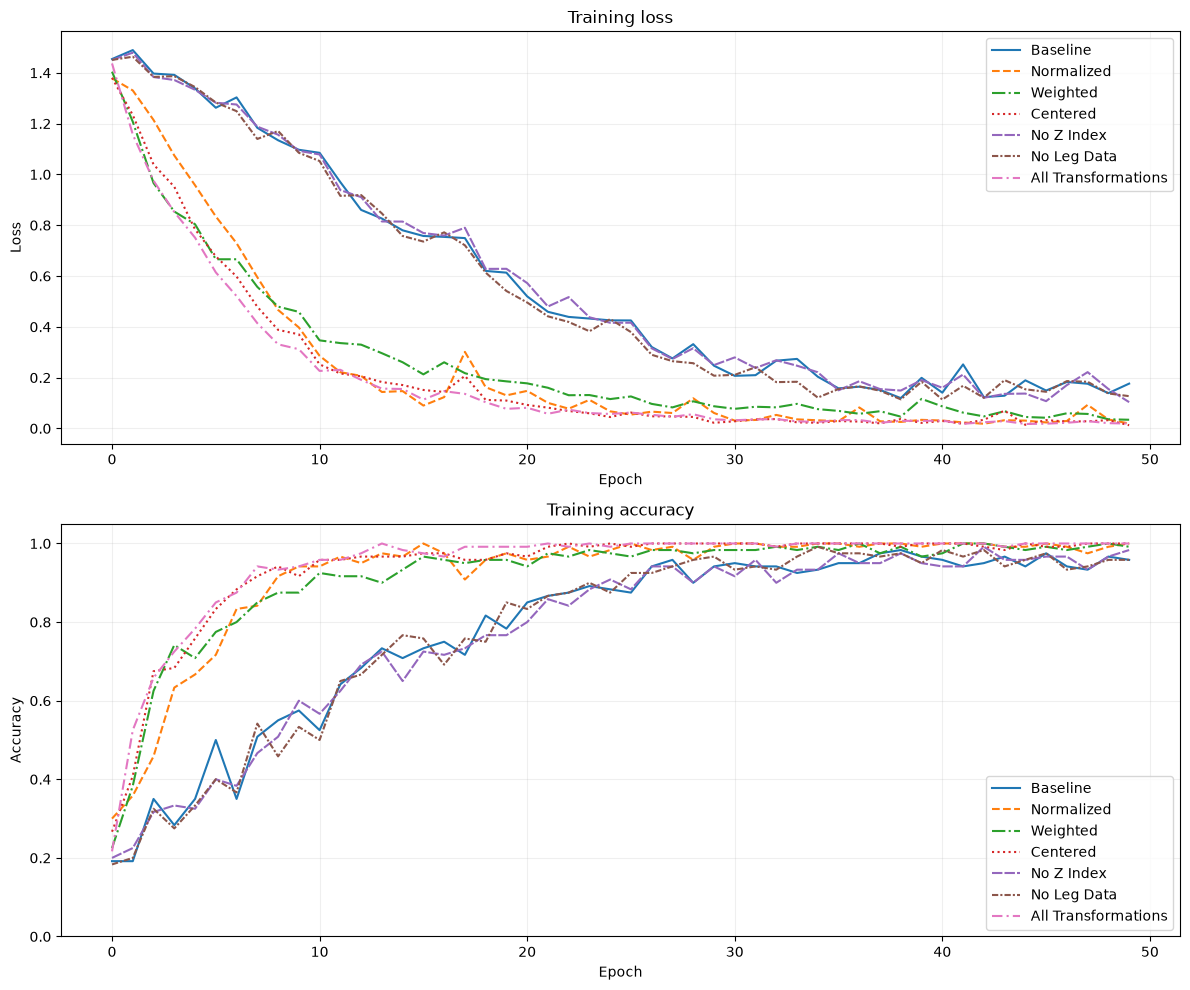

In [30]:
linestyles = ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1)), (0, (5, 2, 1, 2))]

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

for (label, history), linestyle in zip(
    [
        ("Baseline", baseline_training),
        ("Normalized", normalized_training),
        ("Weighted", weighted_training),
        ("Centered", centered_training),
        ("No Z Index", no_z_index_training),
        ("No Leg Data", no_leg_training),
        ("All Transformations", all_transformations_training)
    ],
    linestyles
):
    axes[0].plot(history.history["loss"], label=label, linestyle=linestyle)
    axes[1].plot(history.history["categorical_accuracy"], label=label, linestyle=linestyle)

axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Training accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.05))

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [31]:
def evaluate_models(model_inputs, y_true, actions):

    results = {}

    for name, (model, x) in model_inputs.items():

        y_pred = predictions(model, x)

        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=np.arange(len(actions))
        )

        results[name] = {
            "Accuracy": accuracy_score(y_true, y_pred),
            "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
            "Macro F1": classification_report(
                y_true,
                y_pred,
                labels=np.arange(len(actions)),
                target_names=actions,
                output_dict=True,
                zero_division=0
            )["macro avg"]["f1-score"],
            "Confusion matrix": cm,
            "Predictions": y_pred
        }

    return results

In [32]:
# 1. Load independent test data
test_raw, test_labels, test_actions = load_dataset(
    DATA_PATH_TEST,
    feature_extracter=feature_extracter
)

# Ensure class indices have the same meaning for both datasets
assert list(test_actions) == list(actions), (
    f"Class mismatch: training={actions}, test={test_actions}"
)

# 2. Apply all transformations
test_normalized = transform_dataset(test_raw, feature_transformer=feature_transformer_normalized)
test_weighted = transform_dataset(test_raw, feature_transformer=feature_transformer_weighted)
test_centered = transform_dataset(test_raw, feature_transformer=feature_transformer_centered)
test_no_z_index = transform_dataset(test_raw, feature_transformer=feature_transformer_no_z_index)
test_no_leg = transform_dataset(test_raw, feature_transformer=feature_transformer_leg_removal)
test_all = transform_dataset(test_raw, feature_transformer=feature_transformer_all)

# 3. Prediction helper
def predictions(model, x):
    return np.argmax(model.predict(x, verbose=0), axis=1)

def class_indices(y):
    y = np.asarray(y)
    return np.argmax(y, axis=1) if y.ndim > 1 and y.shape[-1] > 1 else y.reshape(-1)

y_true = class_indices(test_labels)

# 4. Evaluate both models on exactly the same recordings
model_inputs = {
    "Baseline": (baseline_model, test_raw),
    "Normalized": (normalized_model, test_normalized),
    "Weighted": (weighted_model, test_weighted),
    "Centered": (centered_model, test_centered),
    "No Z Index": (no_z_index_model, test_no_z_index),
    "No Leg Data": (no_leg_model, test_no_leg),
    "All Transformations": (all_transformations_model, test_all)
}

results = {}
predictions_by_model = {}
confusion_matrices = {}

results = evaluate_models(model_inputs=model_inputs,
                          y_true=y_true,
                          actions=actions)

for name, result in results.items():

    print(f"\n{'=' * 50}")
    print(name)
    print(f"{'=' * 50}")

    print("Classification report:")
    print(classification_report(
        y_true,
        result["Predictions"],
        labels=np.arange(len(actions)),
        target_names=actions,
        zero_division=0
    ))

    print("Confusion matrix:")
    print(result["Confusion matrix"])
    
# 5. Overall comparison
print("\nOverall comparison")
print(f"Test samples: {len(y_true)}")

for metric in ["Accuracy", "Balanced accuracy", "Macro F1"]:
    baseline = results["Baseline"][metric]
    transformed = results["All Transformations"][metric]

    print(
        f"{metric:20s}: "
        f"Baseline={baseline:.3f}, "
        f"All transformations={transformed:.3f}, "
        f"Difference={(transformed - baseline) * 100:+.2f} pp"
    )



Baseline
Classification report:
              precision    recall  f1-score   support

        idle       0.24      0.33      0.28        30
        poes       0.52      0.50      0.51        30
      slapen       0.57      0.27      0.36        30
       vogel       0.49      0.57      0.52        30

    accuracy                           0.42       120
   macro avg       0.45      0.42      0.42       120
weighted avg       0.45      0.42      0.42       120

Confusion matrix:
[[10  3  2 15]
 [14 15  0  1]
 [14  6  8  2]
 [ 4  5  4 17]]

Normalized
Classification report:
              precision    recall  f1-score   support

        idle       0.29      0.67      0.40        30
        poes       0.94      0.50      0.65        30
      slapen       1.00      0.30      0.46        30
       vogel       0.60      0.50      0.55        30

    accuracy                           0.49       120
   macro avg       0.71      0.49      0.51       120
weighted avg       0.71      0.49     

# Confusion matrices

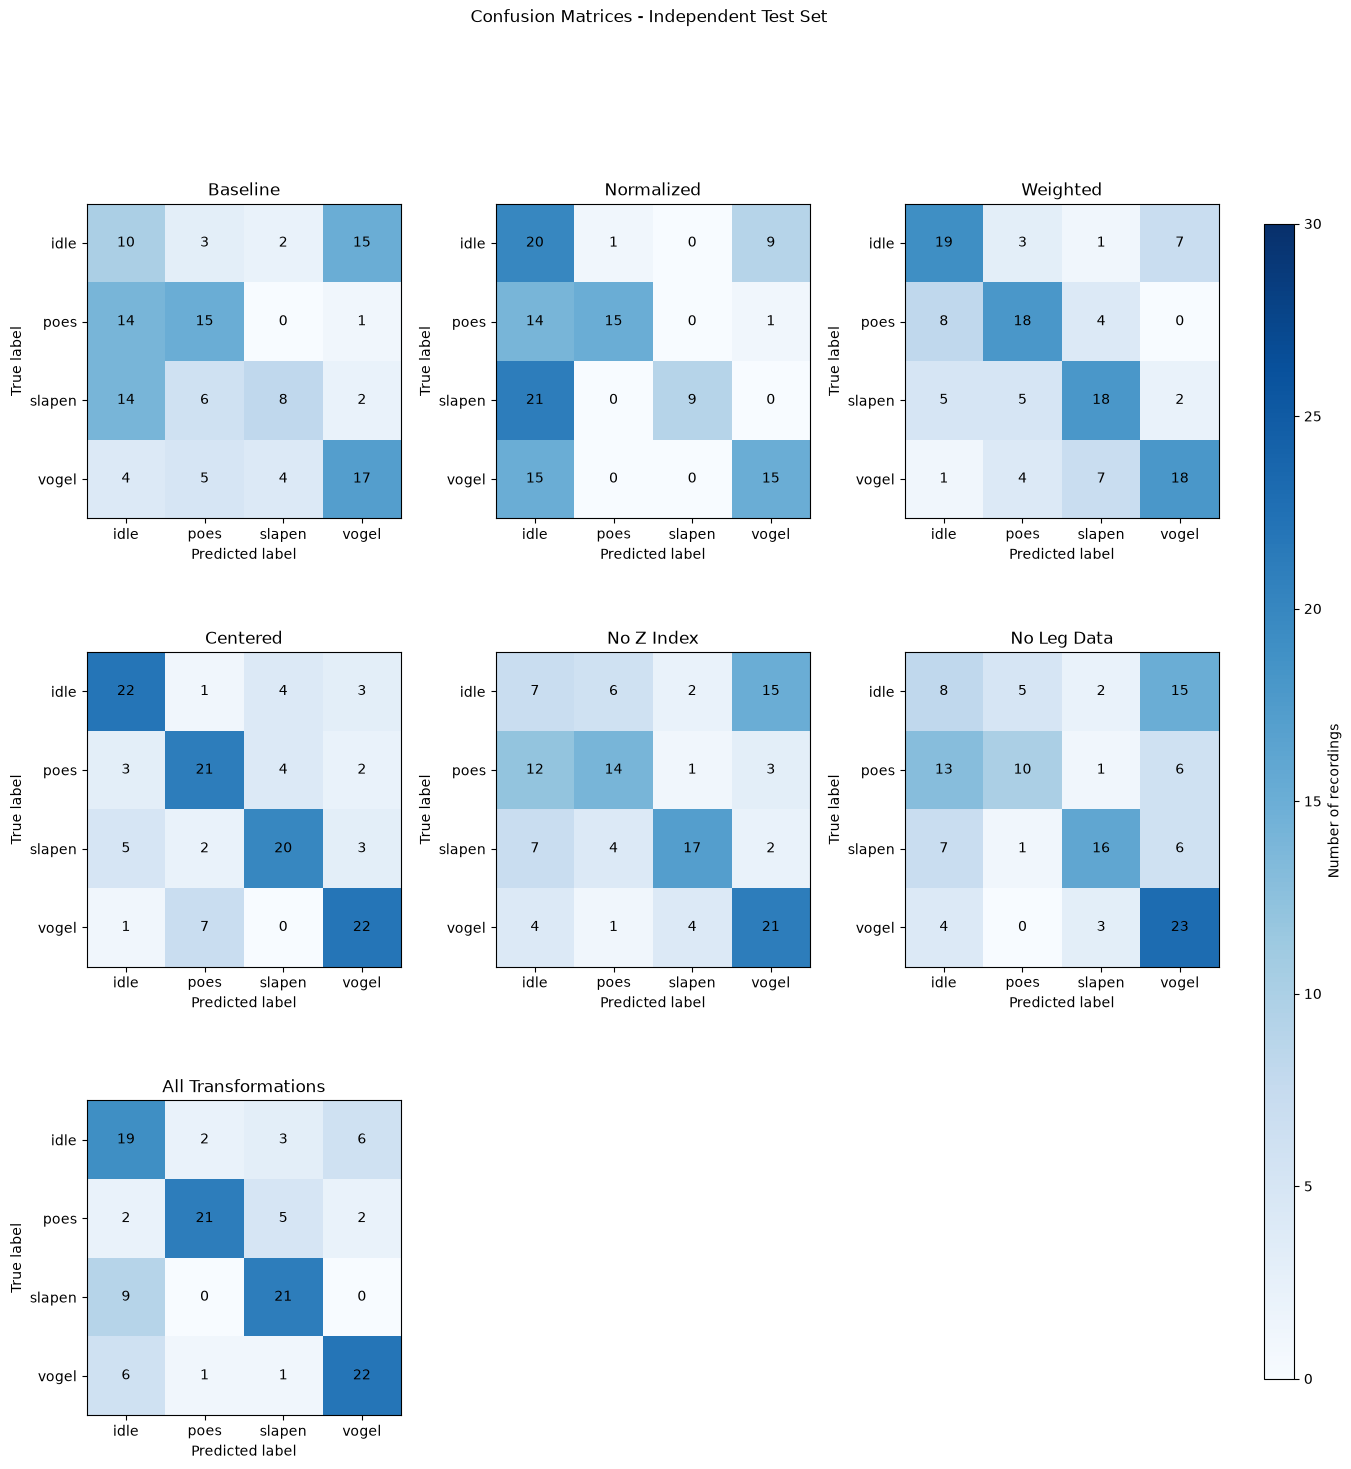

In [ ]:
model_names = list(results.keys())

# Plot confusion matrices
n_models = len(model_names)
n_cols = min(n_models, 3)
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(5 * n_cols, 5 * n_rows),
    squeeze=False
)

axes = axes.flatten()

for ax, name in zip(
    axes,
    model_names
):
    cm = results[name]["Confusion matrix"]

    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=30)

    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(len(actions)), actions)
    ax.set_yticks(range(len(actions)), actions)

    for i in range(len(actions)):
        for j in range(len(actions)):
            ax.text(j, i, cm[i, j], ha="center", va="center")

# remove unused axes (otherwise it shows an empty confusion matrix)
for i in range(n_models, len(axes)):
    fig.delaxes(axes[i])

fig.subplots_adjust(right=0.88, wspace=0.3)
cbar_ax = fig.add_axes([0.91, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax, label="Number of recordings")

fig.suptitle("Confusion Matrices - Independent Test Set")
plt.show()


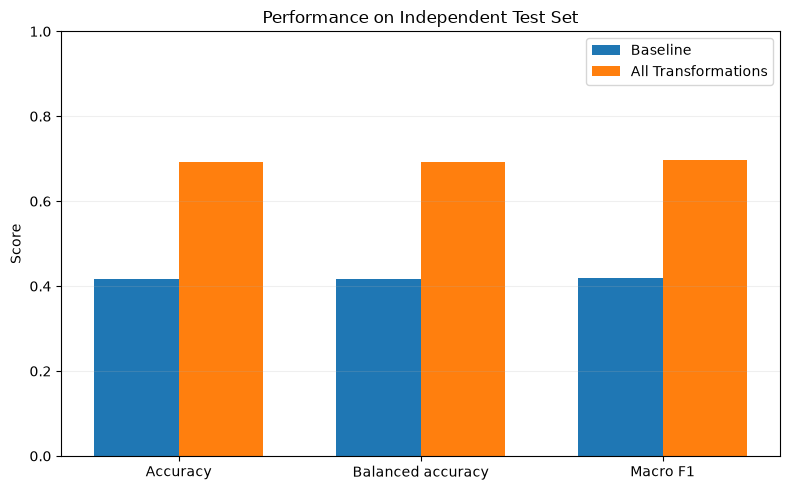

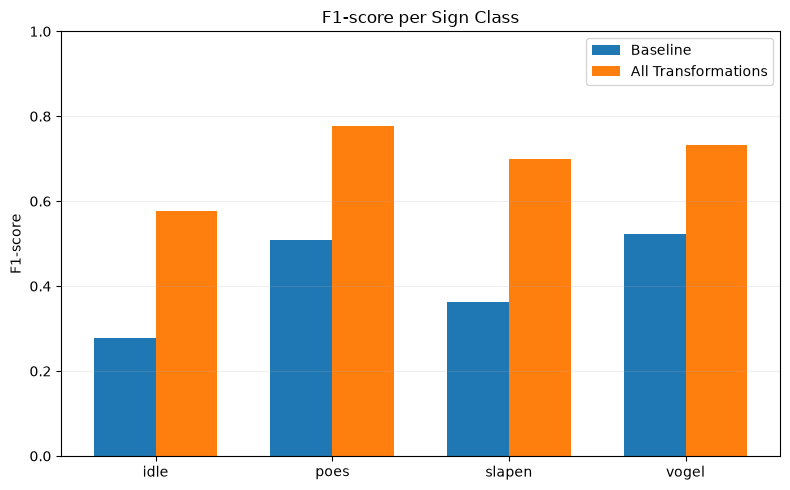

In [34]:
# Compare overall performance
metrics = ["Accuracy", "Balanced accuracy", "Macro F1"]

baseline_scores = [results["Baseline"][m] for m in metrics]
combined_scores = [results["All Transformations"][m] for m in metrics]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(x - width/2, baseline_scores, width, label="Baseline")
ax.bar(x + width/2, combined_scores, width, label="All Transformations")

ax.set_ylabel("Score")
ax.set_title("Performance on Independent Test Set")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


# Compare F1-score per sign class
baseline_report = classification_report(
    y_true,
    results["Baseline"]["Predictions"],
    labels=np.arange(len(actions)),
    target_names=actions,
    output_dict=True,
    zero_division=0
)

combined_report = classification_report(
    y_true,
    results["All Transformations"]["Predictions"],
    labels=np.arange(len(actions)),
    target_names=actions,
    output_dict=True,
    zero_division=0
)

baseline_f1 = [baseline_report[c]["f1-score"] for c in actions]
combined_f1 = [combined_report[c]["f1-score"] for c in actions]

x = np.arange(len(actions))

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(x - width/2, baseline_f1, width, label="Baseline")
ax.bar(x + width/2, combined_f1, width, label="All Transformations")

ax.set_ylabel("F1-score")
ax.set_title("F1-score per Sign Class")
ax.set_xticks(x)
ax.set_xticklabels(actions)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()